In [1]:
%pip install --upgrade torchao==0.17.0 --index-url https://download.pytorch.org/whl/cu130

Looking in indexes: https://download.pytorch.org/whl/cu130
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 60.4 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [2]:
%pip show torchao

Name: torchao
Version: 0.17.0+cu130
Summary: Package for applying ao techniques to GPU models
Home-page: https://github.com/pytorch/ao
Author: 
Author-email: 
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: 
Required-by: 


In [3]:
%pip install -q \
 "transformers==5.2.0" \
 "trl==1.16.0" \
 "peft==0.21.2" \
 "accelerate" \
 "datasets"

## Часть A. Подготовка и анализ данных

In [4]:
from datasets import load_dataset

ds = load_dataset("argilla/ultrafeedback-binarized-preferences-cleaned", split='train')

README.md:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  143MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/60917 [00:00<?, ? examples/s]

In [ ]:
#просмотр формата данных

print(ds.column_names)
print(ds.shape)
print(ds[0]["prompt"])
for ch in ds[0]["chosen"]:
  print(ch)
for r in ds[0]["rejected"]:
  print(r)

['source', 'prompt', 'chosen', 'chosen-rating', 'chosen-model', 'rejected', 'rejected-rating', 'rejected-model']
(60917, 8)
Can you write a C++ program that prompts the user to enter the name of a country and checks if it borders the Mediterranean Sea? Here's some starter code to help you out:
#include <iostream>
#include <string>
using namespace std;
int main() {
    string country;
    // prompt user for input
    cout << "Enter the name of a country: ";
    cin >> country;
    // check if country borders the Mediterranean Sea
    // [C++ code]
    return 0;
}
{'content': 'Can you write a C++ program that prompts the user to enter the name of a country and checks if it borders the Mediterranean Sea? Here\'s some starter code to help you out:\n#include <iostream>\n#include <string>\nusing namespace std;\nint main() {\n    string country;\n    // prompt user for input\n    cout << "Enter the name of a country: ";\n    cin >> country;\n    // check if country borders the Mediterranean S

In [5]:
#1. Корректно извлеките запрос, предпочтительный и отвергнутый ответы.
#Так как дальше нужно будет отфильтровать датасет по разница chosen-rating и rejected-rating, эти столбцы пока оставим

data = ds.select_columns(["prompt", "chosen", "rejected", "chosen-rating", "rejected-rating"])
print(data.column_names)

['prompt', 'chosen', 'rejected', 'chosen-rating', 'rejected-rating']


In [6]:
#3. Удалите примеры с пустыми или одинаковыми ответами

print("Before:", data.shape[0])

def drop_incorrect(example):
  prompt = example["prompt"]
  chosen = example["chosen"]
  rejected = example["rejected"]

  #пустые ответы
  if (not chosen or not rejected):
    return False

  #одинаковые ответы
  if chosen == rejected:
    return False

  return True

data = data.filter(drop_incorrect)

print("After:", data.shape[0])

Before: 60917


Filter:   0%|          | 0/60917 [00:00<?, ? examples/s]

After: 60855


In [7]:
#4. Оставьте пары, для которых разница исходных оценок chosen-rating − rejected-rating составляет не менее 1.

def rating_difference(example):
  return (example["chosen-rating"] - example["rejected-rating"]) >= 1

print("Before:", data.shape[0])

data = data.filter(rating_difference)

print("After:", data.shape[0])

#теперь можно удалить эти столбцы
data = data.remove_columns(["chosen-rating", "rejected-rating"])
print(data.column_names)


Before: 60855


Filter:   0%|          | 0/60855 [00:00<?, ? examples/s]

After: 33411
['prompt', 'chosen', 'rejected']


In [8]:
#2. Обеспечьте корректное форматирование запросов и ответов в соответствии с chat template модели Qwen2.5-Instruct.
#Форматирую примеры в соответвии с форматом, который ожидает на вход DPOTrainer
def format(example):
  prompt = {
      "role": "user",
      "content": example["prompt"]}
  chosen = example["chosen"][1]
  rejected = example["rejected"][1]

  return {"prompt": [prompt],
          "chosen": [chosen],
          "rejected": [rejected]}

data = data.map(format)
print(data[0])

Map:   0%|          | 0/33411 [00:00<?, ? examples/s]

{'prompt': [{'content': 'Can you write a C++ program that prompts the user to enter the name of a country and checks if it borders the Mediterranean Sea? Here\'s some starter code to help you out:\n#include <iostream>\n#include <string>\nusing namespace std;\nint main() {\n    string country;\n    // prompt user for input\n    cout << "Enter the name of a country: ";\n    cin >> country;\n    // check if country borders the Mediterranean Sea\n    // [C++ code]\n    return 0;\n}', 'role': 'user'}], 'chosen': [{'content': 'Here\'s a C++ program that prompts the user to enter the name of a country and checks if it borders the Mediterranean Sea:\n\n#include <iostream>\n#include <string>\n#include <set>\n#include <map>\n#include <algorithm>\n\nusing namespace std;\n\nint main() {\n    // store countries and their bordering seas in a map\n    map<string, set<string>> countries;\n    countries["Algeria"] = {"Mediterranean Sea", "North African Coast"};\n    countries["France"] = {"Mediterranea

In [9]:
#5. Ограничьте длину каждой последовательности prompt + response величиной 512
#токенов с учётом специальных токенов и фактической токенизации. Ни один из ответов
#не должен быть усечён.

from transformers import AutoTokenizer

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

MAX_TOKENS = 512

def get_token_length(messages):
    tokens = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=False
    )
    return len(tokens["input_ids"])


def is_within_limit(example):
    chosen_length = get_token_length(
        example["prompt"] + example["chosen"]
    )

    rejected_length = get_token_length(
        example["prompt"] + example["rejected"]
    )

    return chosen_length <= MAX_TOKENS and rejected_length <= MAX_TOKENS


data = data.filter(is_within_limit)
print(data.shape[0])




config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Filter:   0%|          | 0/33411 [00:00<?, ? examples/s]

19028


In [10]:
#6. Для основного эксперимента оставьте пары, у которых отношение длины более
#длинного ответа к более короткому не превышает 1,25.

#Длину измеряем в токенах
def lengths_ratio(example):
  chosen_l = get_token_length(example["chosen"])
  rejected_l = get_token_length(example["rejected"])

  ratio = max(chosen_l, rejected_l) / min(chosen_l, rejected_l)

  return ratio <= 1.25

data = data.filter(lengths_ratio)
print(data.shape[0])

Filter:   0%|          | 0/19028 [00:00<?, ? examples/s]

4371


In [11]:
#7. Сформируйте обучающую выборку из 1000 пар и оценочную выборку из 200 пар
#8. Зафиксируйте seed=42 и порядок операций подготовки.
data_split = data.train_test_split(train_size=1000, test_size=200, seed=42)
print(data_split)

DatasetDict({
    train: Dataset({
        features: ['prompt', 'chosen', 'rejected'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['prompt', 'chosen', 'rejected'],
        num_rows: 200
    })
})


In [12]:
train = data_split["train"]
eval = data_split["test"]

In [11]:
#9. Исключите пересечение одинаковых запросов между обучающей и оценочной
#выборками. При проверке повторов учитывайте несущественные различия форматирования текста.

import re

def normalize(text):
    text = text.lower()
    text = text.strip()

    # Убираем лишние пробелы
    text = re.sub(r'\s+', ' ', text)

    # Убираем пробелы перед знаками препинания
    text = re.sub(r'\s+([.,!?;:])', r'\1', text)

    # Добавляем пробел после знаков препинания, если его нет
    text = re.sub(r'([.,!?;:])(?=\S)', r'\1 ', text)

    return text.strip()


train_prompts = {
    normalize(example["prompt"][0]["content"])
    for example in train
}

eval_prompts = {
    normalize(example["prompt"][0]["content"])
    for example in eval
}

intersection = train_prompts & eval_prompts

print("Количество пересечений:", len(intersection))



Количество пересечений: 0


В Notebook представьте:
* размеры исходного и отфильтрованного датасета (было выше);
* статистику длин chosen и rejected;
* долю пар, где chosen короче rejected;
* статистику разницы исходных оценок;
* проверку отсутствия пересечения запросов (было выше);
* краткий анализ возможных смещений в данных.

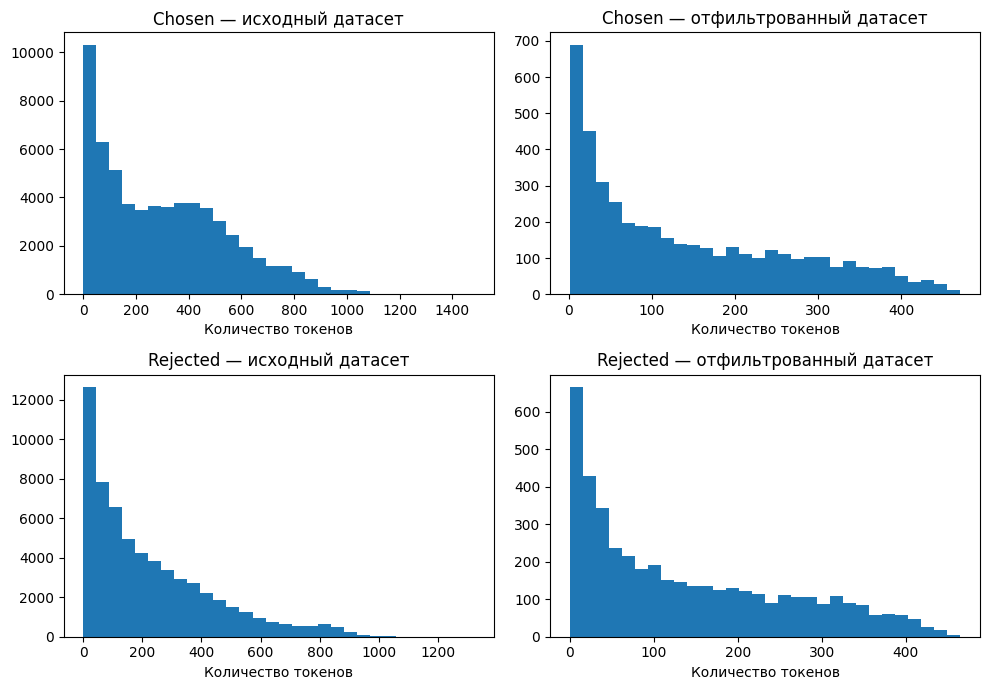

In [11]:
import matplotlib.pyplot as plt

#статистика длин chosen и rejected
def get_answer_length(messages, tokenizer):
  text = " ".join(
        msg["content"]
        for msg in messages
        if msg["role"] == "assistant")

  return len(tokenizer(text, add_special_tokens=False)["input_ids"])

#Статистика для исходного датасета
chosen_ds_lengths = [get_answer_length(row["chosen"], tokenizer) for row in ds]
rejected_ds_lengths = [get_answer_length(row["rejected"], tokenizer) for row in ds]

#Статистика для отфильтрованного
chosen_data_lengths = [get_answer_length(row["chosen"], tokenizer) for row in data]
rejected_data_lengths = [get_answer_length(row["rejected"], tokenizer) for row in data]

fig, ax = plt.subplots(2, 2, figsize = (10, 7))

ax[0, 0].hist(chosen_ds_lengths, bins=30)
ax[0, 0].set_title("Chosen — исходный датасет")
ax[0, 0].set_xlabel("Количество токенов")

ax[0, 1].hist(chosen_data_lengths, bins=30)
ax[0, 1].set_title("Chosen — отфильтрованный датасет")
ax[0, 1].set_xlabel("Количество токенов")

ax[1, 0].hist(rejected_ds_lengths, bins=30)
ax[1, 0].set_title("Rejected — исходный датасет")
ax[1, 0].set_xlabel("Количество токенов")

ax[1, 1].hist(rejected_data_lengths, bins=30)
ax[1, 1].set_title("Rejected — отфильтрованный датасет")
ax[1, 1].set_xlabel("Количество токенов")

plt.tight_layout()
plt.show()

In [12]:
import pandas as pd

length_stats = pd.DataFrame({
    "chosen (исходный)": pd.Series(chosen_ds_lengths),
    "rejected (исходный)": pd.Series(rejected_ds_lengths),
    "chosen (отфильтрованный)": pd.Series(chosen_data_lengths),
    "rejected (отфильтрованный)": pd.Series(rejected_data_lengths)
})

display(length_stats.describe())

,chosen (исходный),rejected (исходный),chosen (отфильтрованный),rejected (отфильтрованный)
count,60917.000000,60917.000000,4371.000000,4371.000000
mean,302.626656,226.912619,140.345459,137.810798
std,240.632894,211.526123,124.700434,121.236838
min,0.000000,0.000000,1.000000,0.000000
25%,87.000000,59.000000,30.000000,30.000000
50%,266.000000,162.000000,103.000000,103.000000
75%,470.000000,341.000000,235.000000,227.500000
max,1482.000000,1321.000000,471.000000,465.000000


In [14]:

#доля пар, где chosen короче rejected;
def proportion(example, tokenizer):
  chosen_text = " ".join(
        msg["content"]
        for msg in example["chosen"]
        if msg["role"] == "assistant")

  rejected_text = " ".join(
        msg["content"]
        for msg in example["rejected"]
        if msg["role"] == "assistant")

  chosen_len = len(tokenizer(chosen_text, add_special_tokens=False)["input_ids"])
  rejected_len = len(tokenizer(rejected_text, add_special_tokens=False)["input_ids"])

  return chosen_len < rejected_len

ds_len = ds.shape[0]
ds_proportion_len =  sum([proportion(example, tokenizer) for example in ds])

print("Доля пар, где chosen короче rejected в исходном наборе:", (ds_proportion_len / ds_len) * 100)

data_len = data.shape[0]
data_proportion_len = sum([proportion(example, tokenizer) for example in data])

print("Доля пар, где chosen короче rejected в отфильтрованом наборе:", (data_proportion_len / data_len) * 100)

Доля пар, где chosen короче rejected в исходном наборе: 34.044683750020525
Доля пар, где chosen короче rejected в отфильтрованом наборе: 43.788606726149624


In [18]:
#статистика разницы исходных оценок;
diff_ds = [c - r for c, r in zip(ds["chosen-rating"], ds["rejected-rating"])]

diff_stats = pd.DataFrame({"Разница оценок (исходный)": pd.Series(diff_ds)})

display(diff_stats.describe())


,Разница оценок (исходный)
count,60917.000000
mean,1.316734
std,0.999469
min,0.250000
25%,0.500000
50%,1.000000
75%,2.000000
max,4.000000


Краткий анализ смещения данных:

Некоторые смещения могли произойти из-за фильтрации данных, например:
1. Мы удалили примеры, где разница оценок меньше 1, оставив только примеры с большим разрывом. Т.е. модель в теории может хуже различать небольшие изменения в тональности текста, которые всё ещё влияют на восприятие пользователя.
2. Мы удалили сликшом длинные последовательности, из-за чего модель может начать хуже справляться с длинными текстами (более 512 токенов) из-за их недостаточной представленности в наборе.

## Часть B. Самостоятельная реализация DPO loss

In [11]:

import torch
import torch.nn.functional as F

#DPO Loss
def dpo_loss(
    policy_chosen_logps,
    policy_rejected_logps,
    ref_chosen_logps,
    ref_rejected_logps,
    beta):

  # Reference model не обучается
  ref_chosen_logps = ref_chosen_logps.detach()
  ref_rejected_logps = ref_rejected_logps.detach()

  # Разница между policy и reference для chosen
  chosen_logratios = policy_chosen_logps - ref_chosen_logps

  # Разница между policy и reference для rejected
  rejected_logratios = policy_rejected_logps - ref_rejected_logps

  # Насколько policy предпочитает chosen относительно rejected
  logits = beta * (chosen_logratios - rejected_logratios)

  # DPO Loss для каждой пары
  losses = -F.logsigmoid(logits)

  # Среднее значение по батчу
  return losses.mean()


In [22]:
#Проверка на синтетических данных
import torch
from math import log

def police_ref_test():
  '''Тест с совпадением police и reference моделей'''

  policy_chosen = torch.tensor(-2.0, requires_grad=True)

  policy_rejected = torch.tensor(-2.0, requires_grad=True)

  ref_chosen = torch.tensor(-2.0)
  ref_rejected = torch.tensor(-2.0)

  beta = 0.1

  # Вычисляем loss
  loss = dpo_loss(
      policy_chosen,
      policy_rejected,
      ref_chosen,
      ref_rejected,
      beta
  )

  print("DPO Loss:", "%.4f" % loss.item())
  print("ln 2:", "%.4f" % log(2))
  assert round(log(2), 4) == round(loss.item(), 4)

def loss2_test():
  '''Тест с изменением loss, при увеличении значений chosen'''

  beta = 0.1

  ref_chosen = torch.tensor([-3.0])
  ref_rejected = torch.tensor([-4.0])

  # Первый вариант: меньшее преимущество chosen
  policy_chosen_1 = torch.tensor([-2.0])
  policy_rejected_1 = torch.tensor([-5.0])

  loss_1 = dpo_loss(
      policy_chosen_1,
      policy_rejected_1,
      ref_chosen,
      ref_rejected,
      beta
  )

  # Второй вариант: большее преимущество chosen
  policy_chosen_2 = torch.tensor([-1.0])
  policy_rejected_2 = torch.tensor([-5.0])

  loss_2 = dpo_loss(
      policy_chosen_2,
      policy_rejected_2,
      ref_chosen,
      ref_rejected,
      beta
  )

  print("Первый loss:", "%.4f" % loss_1.item())
  print("Второй loss:", "%.4f" % loss_2.item())

  assert loss_2 < loss_1

def batch_test():
  '''Тест с обработкой батчей'''

  policy_chosen = torch.tensor(
      [-2.0, -3.0, -1.5],
      requires_grad=True
  )

  policy_rejected = torch.tensor(
      [-5.0, -4.0, -3.0],
      requires_grad=True
  )

  ref_chosen = torch.tensor([-3.0, -3.5, -2.0])
  ref_rejected = torch.tensor([-4.0, -3.0, -2.5])

  beta = 0.1

  # Вычисляем loss
  loss = dpo_loss(
      policy_chosen,
      policy_rejected,
      ref_chosen,
      ref_rejected,
      beta
  )
  individual_losses = []

  #Проверяем, что вычесленный loss - усреднение по каждой паре
  for i in range(3):
      individual_loss = dpo_loss(
          policy_chosen[i],
          policy_rejected[i],
          ref_chosen[i],
          ref_rejected[i],
          beta
      )
      individual_losses.append(individual_loss)

  expected_loss = torch.stack(individual_losses).mean()

  print("DPO Loss:", "%.4f" % loss.item())
  print("Expected DPO loss:", "%.4f" % expected_loss.item())

  assert torch.allclose(loss, expected_loss)

police_ref_test()
print("-"*10)
loss2_test()
print("-"*10)
batch_test()

DPO Loss: 0.6931
ln 2: 0.6931
----------
Первый loss: 0.5981
Второй loss: 0.5544
----------
DPO Loss: 0.6212
Expected DPO loss: 0.6212


1. Первый тест выполняеться, так как все разницы оценко дадут 0 и в конечной функции мы получим:


> -ln(sigm(0)) = -ln(1/2) = ln(2) (по св-ву логарифма)

2. Во втором тесте значение loss уменьшиться при увеличении оценок chosen, так как
в в конечной функции loss будет большее число. После применения сигмоиды к этому числу, мы получим большее число в диапазон от 0 до 1. Натуральный логарифм от этого числа даст большее отрицательное число (либо 0 на x = 1). После этого мы снимем отрицание минусом перед логарифмом и в итоге получим меньший loss.

3. А последний тест показыват, что loss для батча вычисляеться как усреднённое между всеми отдельными примерами. Это обеспечиваеться loss.mean() в алгориитме




## Часть C. Дообучение модели с LoRA

In [18]:
from trl import DPOTrainer, DPOConfig
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig
import torch
import time

model_name = "Qwen/Qwen2.5-0.5B-Instruct"

policy_model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16)

lora_conf = LoraConfig(r=8,
                       lora_dropout=0,
                       lora_alpha=16,
                       target_modules=['q_proj', 'v_proj'])


training_args = DPOConfig(learning_rate=5e-5,
                          per_device_train_batch_size=1,
                          gradient_accumulation_steps=4,
                          max_length=512,
                          beta=0.1,
                          max_steps=250,
                          seed=42,
                          fp16=True, #Без настройки типов была ошибка
                          bf16=False)

trainer = DPOTrainer(model=policy_model,
                     train_dataset=train,
                     eval_dataset=eval,
                     args=training_args,
                     peft_config = lora_conf)

#Проверка, что обучаеться только часть параметров
trainer.model.print_trainable_parameters()

#Подсчёт затраченой памяти на обучения
if torch.cuda.is_available():

    device = torch.cuda.current_device()

    # Сбрасываем предыдущие показатели памяти
    torch.cuda.reset_peak_memory_stats(device)

    # Обучение
    train_result = trainer.train()

    # Получаем пиковую память
    peak_allocated = torch.cuda.max_memory_allocated(device) / (1024 ** 3)

    print("Пиковая выделенная GPU память (ГБ):", "%.2f" % peak_allocated)

else:
    print("Обучение без GPU")
    train_result = trainer.train()

trainer.model.save_pretrained("./lora_adapter")

eval_metrics = trainer.evaluate()

print(train_result.metrics) #Время обучения выводиться в метриках
print(eval_metrics)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093


Step,Training Loss
10,0.690715
20,0.681897
30,0.661454
40,0.664639
50,0.655750
60,0.606750
70,0.640931
80,0.528966
90,0.561945
100,0.631146


Пиковая выделенная GPU память (ГБ): 2.87


{'train_runtime': 328.9324, 'train_samples_per_second': 3.04, 'train_steps_per_second': 0.76, 'total_flos': 1222823947901952.0, 'train_loss': 0.5849096832275391, 'epoch': 1.0}
{'eval_loss': 0.5692111849784851, 'eval_runtime': 23.0248, 'eval_samples_per_second': 8.686, 'eval_steps_per_second': 1.086, 'eval_entropy': 1.1780495476722717, 'eval_num_tokens': 551772.0, 'eval_logits/chosen': -2.0833275072460893, 'eval_logits/rejected': -2.040477372014537, 'eval_mean_token_accuracy': 0.6724970674514771, 'eval_rewards/chosen': -0.8285038232803345, 'eval_rewards/rejected': -1.544380624294281, 'eval_rewards/accuracies': 0.735, 'eval_rewards/margins': 0.7158768039941787, 'eval_logps/chosen': -193.38422119140625, 'eval_logps/rejected': -213.78209564208984, 'epoch': 1.0}


## Часть D. Исследовательский эксперимент

Исследуем влияние парамтра beta.

Гипотеза: beta отвечает за силу влияния предпочитаемых ответетов на модель. Чем больше beta - тем больше модель учитывает различия между chosen и rejected и тем больше обучаемая модель может отходить от исходной. Скорее всего, благодрая этому можно добиться меньшего loss, при уловии, что модель изначально отдаёт большее предпочтение chosen. В обраном случае, с увеличением beta loss будет ухудшаться.  

In [19]:
from trl import DPOTrainer, DPOConfig
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig
import torch
import time

policy_model = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=torch.float16)

lora_conf = LoraConfig(r=8,
                       lora_dropout=0,
                       lora_alpha=16,
                       target_modules=['q_proj', 'v_proj'])
# beta = 0.5
training_args_1 = DPOConfig(learning_rate=5e-5,
                          per_device_train_batch_size=1,
                          gradient_accumulation_steps=4,
                          max_length=512,
                          beta=0.5,
                          max_steps=250,
                          seed=42,
                          fp16=True,
                          bf16=False)

trainer_1 = DPOTrainer(model=policy_model,
                     train_dataset=train,
                     eval_dataset=eval,
                     args=training_args_1,
                     peft_config = lora_conf)

#Проверка, что обучаеться только часть параметров
trainer_1.model.print_trainable_parameters()

#Подсчёт затраченой памяти на обучения
if torch.cuda.is_available():

    device = torch.cuda.current_device()

    # Сбрасываем предыдущие показатели памяти
    torch.cuda.reset_peak_memory_stats(device)

    # Обучение
    train_result_1 = trainer_1.train()

    # Получаем пиковую память
    peak_allocated = torch.cuda.max_memory_allocated(device) / (1024 ** 3)

    print("Пиковая выделенная GPU память (ГБ):", "%.2f" % peak_allocated)

else:
    print("Обучение без GPU")
    train_result_1 = trainer_1.train()

trainer_1.model.save_pretrained("./lora_adapter_1")
eval_metrics_1 = trainer_1.evaluate()

print(train_result_1.metrics) #Время обучения выводиться в метриках
print(eval_metrics_1)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Dropping fully truncated examples from train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dropping fully truncated examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.


trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093


Step,Training Loss
10,0.684372
20,0.636856
30,0.592007
40,0.648534
50,0.622166
60,0.512476
70,0.663135
80,0.418665
90,0.460377
100,0.713399


Пиковая выделенная GPU память (ГБ): 3.00


{'train_runtime': 322.0908, 'train_samples_per_second': 3.105, 'train_steps_per_second': 0.776, 'total_flos': 1222823947901952.0, 'train_loss': 0.5626725273132325, 'epoch': 1.0}
{'eval_loss': 0.6154332160949707, 'eval_runtime': 22.9712, 'eval_samples_per_second': 8.707, 'eval_steps_per_second': 1.088, 'eval_entropy': 1.1834576106071473, 'eval_num_tokens': 551772.0, 'eval_logits/chosen': -2.0255426600226984, 'eval_logits/rejected': -2.0011075197903367, 'eval_mean_token_accuracy': 0.6768666648864746, 'eval_rewards/chosen': -1.4183366870880127, 'eval_rewards/rejected': -2.5781265115737915, 'eval_rewards/accuracies': 0.73, 'eval_rewards/margins': 1.1597898292541504, 'eval_logps/chosen': -187.93585571289063, 'eval_logps/rejected': -203.4945394897461, 'epoch': 1.0}


Вывод: При увеличении beta с 0,1 до 0,5 значение train_loss увеньшилось с примерно 0,58 до 0,56. Это согласуется с первоначальной гипотезой о влиянии beta на оптимизацию предпочтений.

Beta масштабирует разницу между относительными log probabilities предпочтительного и нежелательного ответов. При положительном значении этой разницы увеличение beta приводит к уменьшению DPO loss.

Однако eval loss, напротив, увеличился с 0.56 до 0.61. Это может говорить о том, что модель с большим значением beta лучше оптимизировала обучающую выборку, но не продемонстрировала улучшения на новых примерах.

Доля правильно ранжированных пар (eval rewards/accuracies) практически не изменилась: 73.5% при beta = 0.1 и 73% при beta = 0.5. Таким образом, увеличение beta привело к изменению масштаба разделения предпочтений, но не обеспечило улучшения точности ранжирования на оценочной выборке.

In [20]:
from google.colab import drive
import os

drive.mount('/content/drive')

#Сохранение полученных адаптеров
trainer.model.save_pretrained("/content/drive/MyDrive/DPO_experiments/lora_adapter")
trainer_1.model.save_pretrained("/content/drive/MyDrive/DPO_experiments/lora_adapter_1")

#Сохранение метрик
trainer.save_metrics("train", train_result.metrics)
trainer_1.save_metrics("train_1", train_result_1.metrics)

Mounted at /content/drive


## Часть E. Оценка результатов (Evaluation)

In [21]:
#Вспомогательный метода получения logps
def extract_pair_logps(output):
    # Вариант, когда результат — словарь
    if isinstance(output, dict):
        return output["chosen_logps"], output["rejected_logps"]

    # Вариант, когда результат — кортеж
    return output[0], output[1]

In [33]:
import torch

def collect_logps(trainer):
  '''Вычисляет нужные log probabilities для каждой пары примеров'''
  trainer.model.eval()

  all_policy_chosen = []
  all_policy_rejected = []
  all_ref_chosen = []
  all_ref_rejected = []
  all_chosen_lengths = []
  all_rejected_lengths = []

  dataloader = trainer.get_eval_dataloader()

  for batch in dataloader:
      batch = trainer._prepare_inputs(batch)

      labels = batch["input_ids"].masked_fill(
            batch["completion_mask"] == 0, -100
        )

      with torch.no_grad(), trainer.compute_loss_context_manager():

          # policy log probabilities
          policy_output = trainer.model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                labels=labels,
                use_cache=False,
                fused_lm_head=True
            )

          policy_per_token_logps = policy_output.log_probs

          shift_mask = batch["completion_mask"][..., 1:]
          policy_per_token_logps = policy_per_token_logps[
                :, -shift_mask.size(1):
            ]

          policy_logps = (
                policy_per_token_logps * shift_mask
            ).sum(dim=1)

          policy_chosen, policy_rejected = policy_logps.chunk(2, dim=0)

          # Reference log probabilities
          ref_chosen, ref_rejected = trainer.compute_ref_log_probs(
                trainer.model, batch
            )

          # Completion lengths
          lengths = shift_mask.sum(dim=1)
          chosen_lengths, rejected_lengths = lengths.chunk(2, dim=0)

      # Gather results across devices
      gathered = trainer.accelerator.gather_for_metrics((
          policy_chosen,
          policy_rejected,
          ref_chosen,
          ref_rejected,
          chosen_lengths,
          rejected_lengths
        ))

      (
          policy_chosen,
          policy_rejected,
          ref_chosen,
          ref_rejected,
          chosen_lengths,
          rejected_lengths
      ) = gathered

      all_policy_chosen.append(policy_chosen.cpu())
      all_policy_rejected.append(policy_rejected.cpu())
      all_ref_chosen.append(ref_chosen.cpu())
      all_ref_rejected.append(ref_rejected.cpu())
      all_chosen_lengths.append(chosen_lengths.cpu())
      all_rejected_lengths.append(rejected_lengths.cpu())

  return {
        "policy_chosen": torch.cat(all_policy_chosen),
        "policy_rejected": torch.cat(all_policy_rejected),
        "ref_chosen": torch.cat(all_ref_chosen),
        "ref_rejected": torch.cat(all_ref_rejected),
        "chosen_lengths": torch.cat(all_chosen_lengths),
        "rejected_lengths": torch.cat(all_rejected_lengths)
    }

In [23]:
def calculate_metrics(logps, beta):
  '''Расчёт метрик: DPO reward accuracy
                    Абсолютная preference accuracy
                    Preference accuracy с нормировкой по длине'''

  policy_chosen = logps["policy_chosen"]
  policy_rejected = logps["policy_rejected"]

  ref_chosen = logps["ref_chosen"]

  chosen_lengths = logps["chosen_lengths"]
  rejected_lengths = logps["rejected_lengths"]

  # 1. DPO reward accuracy
  # Сравниваем chosen у policy и reference
  chosen_delta = policy_chosen - ref_chosen #Формула как в задании

  dpo_reward_accuracy = (
        chosen_delta > 0
    ).float().mean().item()

  # Средний reward margin по формуле задания
  mean_reward_margin = chosen_delta.mean().item()

  # Дополнительно: reward с множителем beta
  mean_scaled_reward = (beta * chosen_delta).mean().item() #Стандартная формула

  # 2. Absolute preference accuracy
  # Сравниваем chosen и rejected у policy
  absolute_preference_accuracy = (
        policy_chosen > policy_rejected
    ).float().mean().item()

  # 3. Preference accuracy с нормировкой по длине
  chosen_avg_logps = policy_chosen / chosen_lengths
  rejected_avg_logps = policy_rejected / rejected_lengths

  normalized_preference_accuracy = (
        chosen_avg_logps > rejected_avg_logps
    ).float().mean().item()

  return {
        "DPO reward accuracy": dpo_reward_accuracy,
        "Mean reward margin": mean_reward_margin,
        "Mean scaled reward": mean_scaled_reward,
        "Absolute preference accuracy": absolute_preference_accuracy,
        "Normalized preference accuracy": normalized_preference_accuracy
    }

In [24]:
def calculate_reference_metrics(logps):
  '''Для подсчёта аналогичных метрик для исходной модели'''

  chosen = logps["ref_chosen"]
  rejected = logps["ref_rejected"]

  chosen_lengths = logps["chosen_lengths"]
  rejected_lengths = logps["rejected_lengths"]

  absolute_accuracy = (
        chosen > rejected
    ).float().mean().item()

  normalized_accuracy = (
        chosen / chosen_lengths > rejected / rejected_lengths
    ).float().mean().item()

  return {
        "DPO reward accuracy": 0.0,
        "Mean reward margin": 0.0,
        "Mean scaled reward": 0.0,
        "Absolute preference accuracy": absolute_accuracy,
        "Normalized preference accuracy": normalized_accuracy
    }

In [34]:
# Собираем log probabilities для первой конфигурации
logps_01 = collect_logps(trainer)

# Собираем log probabilities для второй конфигурации
logps_05 = collect_logps(trainer_1)

# Считаем метрики
results_01 = calculate_metrics(logps_01, beta=0.1)
results_05 = calculate_metrics(logps_05, beta=0.5)
results_base = calculate_reference_metrics(logps_01)

In [35]:
import pandas as pd

results_df = pd.DataFrame(
    [results_base, results_01, results_05],
    index=["Base Qwen", "LoRA beta=0.1", "LoRA beta=0.5"]
)

display(results_df)

,DPO reward accuracy,Mean reward margin,Mean scaled reward,Absolute preference accuracy,Normalized preference accuracy
Base Qwen,0.00,0.000000,0.000000,0.585,0.585
LoRA beta=0.1,0.17,-8.285038,-0.828504,0.620,0.620
LoRA beta=0.5,0.19,-2.836673,-1.418337,0.605,0.585


3. Совпадают ли выводы по DPO reward accuracy и абсолютной preference accuracy? Если нет, почему?

Нет, выводы по этим метрикам не полностью совпадают, поскольку они оценивают разные аспекты работы модели.

DPO reward accuracy показывает, насколько часто после обучения модель стала присваивать выбранным ответам более высокую вероятность, чем до обучения.

Absolute preference accuracy показывает, в какой доле примеров модель присваивает chosen более высокую вероятность, чем rejected.


### Анализ конкретных примеров:

In [36]:
import pandas as pd

def create_comparison_table(eval_dataset, logps_01, logps_05):
  '''Создание таблицы с оценками разных моделей для каждого примера из eval'''
  data = []

  for i in range(len(eval_dataset)):
      # Оценки исходной модели
      base_chosen = logps_01["ref_chosen"][i].item()
      base_rejected = logps_01["ref_rejected"][i].item()

      # Оценки модели beta=0.1
      beta01_chosen = logps_01["policy_chosen"][i].item()
      beta01_rejected = logps_01["policy_rejected"][i].item()

      # Оценки модели beta=0.5
      beta05_chosen = logps_05["policy_chosen"][i].item()
      beta05_rejected = logps_05["policy_rejected"][i].item()

      data.append({
            "index": i,

            "base_chosen": base_chosen,
            "base_rejected": base_rejected,
            "base_margin": base_chosen - base_rejected,

            "beta01_chosen": beta01_chosen,
            "beta01_rejected": beta01_rejected,
            "beta01_margin": beta01_chosen - beta01_rejected,

            "beta05_chosen": beta05_chosen,
            "beta05_rejected": beta05_rejected,
            "beta05_margin": beta05_chosen - beta05_rejected,
        })

  return pd.DataFrame(data)

comparison_df = create_comparison_table(eval, logps_01, logps_05)

display(comparison_df.head())

,index,base_chosen,base_rejected,base_margin,beta01_chosen,beta01_rejected,beta01_margin,beta05_chosen,beta05_rejected,beta05_margin
0,0,-1.974184,-2.368572,0.394388,-3.830404,-3.299498,-0.530907,-2.173864,-2.478472,0.304607
1,1,-69.715935,-153.204910,83.488976,-79.010269,-170.698898,91.688629,-74.309647,-160.146606,85.836960
2,2,-32.717678,-38.948116,6.230438,-31.163210,-45.849800,14.686590,-31.574871,-42.830883,11.256012
3,3,-126.776855,-214.251740,87.474884,-146.727005,-223.273117,76.546112,-134.160263,-218.079132,83.918869
4,4,-218.278534,-234.987961,16.709427,-229.238403,-251.162903,21.924500,-220.424515,-240.256439,19.831924


In [37]:
# Корректное предпочтение: все три модели предпочитают chosen
correct = comparison_df[
    (comparison_df["base_margin"] > 0) &
    (comparison_df["beta01_margin"] > 0) &
    (comparison_df["beta05_margin"] > 0)
]

# Изменение предпочтения: исходная модель ошибалась,
# обученные модели предпочитают chosen
changed = comparison_df[
    (comparison_df["base_margin"] < 0) &
    (comparison_df["beta01_margin"] > 0) &
    (comparison_df["beta05_margin"] > 0)
]

# Ошибка ранжирования: обе обученные модели предпочитают rejected
error = comparison_df[
    (comparison_df["beta01_margin"] < 0) &
    (comparison_df["beta05_margin"] < 0)
]

# Отсутствие изменения: знак margin сохранился
same = comparison_df[
    (comparison_df["base_margin"] * comparison_df["beta01_margin"] > 0) &
    (comparison_df["base_margin"] * comparison_df["beta05_margin"] > 0)
]

print("Корректное предпочтение:", len(correct))
print("Изменение предпочтения:", len(changed))
print("Ошибка ранжирования:", len(error))
print("Отсутствие изменения:", len(same))

Корректное предпочтение: 114
Изменение предпочтения: 4
Ошибка ранжирования: 73
Отсутствие изменения: 187


Чисто по количеству примеров в разных категориях можно сказать, что модель изначально ранжировала большую часть ответов правильно.

In [38]:
selected_indices = []

for category in [correct, changed, error, same]:
    if len(category) > 0:
        selected_indices.append(int(category.iloc[0]["index"]))

print("Выбранные индексы:", selected_indices)

Выбранные индексы: [1, 171, 7, 1]


In [39]:
def get_text(messages):
    return "\n".join(
        msg["content"]
        for msg in messages
    )


def show_example(idx, eval_dataset, comparison_df):
    example = eval_dataset[idx]
    scores = comparison_df[
        comparison_df["index"] == idx
    ].iloc[0]

    print("=" * 80)
    print(f"Пример №{idx}")
    print("=" * 80)

    print("\nЗАПРОС:")
    print(get_text(example["prompt"]))

    print("\nCHOSEN:")
    print(get_text(example["chosen"]))

    print("\nREJECTED:")
    print(get_text(example["rejected"]))

    print("\nОЦЕНКИ МОДЕЛЕЙ:")
    results = pd.DataFrame({
        "Модель": ["Base Qwen", "Beta = 0.1", "Beta = 0.5"],
        "Chosen logp": [
            scores["base_chosen"],
            scores["beta01_chosen"],
            scores["beta05_chosen"]
        ],
        "Rejected logp": [
            scores["base_rejected"],
            scores["beta01_rejected"],
            scores["beta05_rejected"]
        ],
        "Margin": [
            scores["base_margin"],
            scores["beta01_margin"],
            scores["beta05_margin"]
        ]
    })

    display(results)

#Выводим выбранные примеры
for idx in selected_indices:
    show_example(idx, eval, comparison_df)

Пример №1

ЗАПРОС:
Mary and Ann are mother and daughter. Mary is in her 70's while Ann is in her late 40's. They both work out regularly for improved health. Mary has been experiencing some health issues lately.  Given the paragraph above, please answer correctly the following question:   Which person has a weaker immune system?  Hint: During late adulthood, the risk of developing diseases such as cardiovascular diseases and cancer continues to rise. Most people also have a decline in strength and stamina. Their senses may start failing, and their reflex time typically increases. Their immune system also doesn’t work as well as it used to. As a result, common diseases like the flu may become more serious and even lead to death. The majority of late adults develop arthritis, and as many as one in four develop Alzheimer’s disease.
A:

CHOSEN:
It is not possible to determine who has a weaker immune system based on the information provided in the paragraph. The paragraph mentions that duri

,Модель,Chosen logp,Rejected logp,Margin
0,Base Qwen,-69.715935,-153.204910,83.488976
1,Beta = 0.1,-79.010269,-170.698898,91.688629
2,Beta = 0.5,-74.309647,-160.146606,85.836960


Пример №171

ЗАПРОС:
Could you give me a recommendation for a Node dev module that would audit usage of deprecated browser APIs?

CHOSEN:
Certainly! One popular module for auditing the usage of deprecated browser APIs in a Node.js project is "eslint-plugin-compat". This module is an ESLint plugin that checks your code against thebrowserslist, which is a spec compat datascarf. This plugin helps you troubleshoot and ensure that your application works with specific browsers or browser versions you want to support.

Here's how you can install it:
```bash
npm install --save-dev eslint-plugin-compat
```
After installing the plugin, you'll need to update your ESLint configuration file (eslintrc.json or .eslintrc.json) to enable the "compat" plugin. Here's an example of how to set it up:
```json
{
  "plugins": [
    "compat"
  ],
  "rules": {
    "compat/compat": "warn"
  }
}
```
In this example, any usage of deprecated browser APIs will result in a warning when running ESLint on your project.

,Модель,Chosen logp,Rejected logp,Margin
0,Base Qwen,-424.565338,-420.744476,-3.820862
1,Beta = 0.1,-431.519623,-455.872559,24.352936
2,Beta = 0.5,-427.620911,-430.472595,2.851685


Пример №7

ЗАПРОС:
Generate response to the question/instruction based on a piece of given material

Question/Instruction: Where is Sen Pad Thai located within Granville Island market?

Given material: Sen Pad Thai is the fifth addition to Chef Angus An’s family of restaurants. Known for its long stir-fried noodles, the Granville Island eatery serves up intense yet balanced dishes seasoned with spices, herbs, and proteins like chicken, pork, beef, and seafood. Chef An also created a selection of delicious side dishes, ranging from Crispy Thai chicken wings to lighter fare like papaya salad. Sen Pad Thai is located in the Net Loft area of Vancouver’s Granville Island market, which buzzes with energy from vendors and visitors alike.

CHOSEN:
Sen Pad Thai is located in the vibrant Net Loft area of Vancouver's Granville Island market, surrounded by a lively atmosphere with various vendors and visitors exploring the diverse offerings in the market. This popular eatery, known for its sumptuo

,Модель,Chosen logp,Rejected logp,Margin
0,Base Qwen,-129.329575,-109.015564,-20.314011
1,Beta = 0.1,-132.943359,-131.341797,-1.601562
2,Beta = 0.5,-130.802551,-116.365730,-14.436821


Пример №1

ЗАПРОС:
Mary and Ann are mother and daughter. Mary is in her 70's while Ann is in her late 40's. They both work out regularly for improved health. Mary has been experiencing some health issues lately.  Given the paragraph above, please answer correctly the following question:   Which person has a weaker immune system?  Hint: During late adulthood, the risk of developing diseases such as cardiovascular diseases and cancer continues to rise. Most people also have a decline in strength and stamina. Their senses may start failing, and their reflex time typically increases. Their immune system also doesn’t work as well as it used to. As a result, common diseases like the flu may become more serious and even lead to death. The majority of late adults develop arthritis, and as many as one in four develop Alzheimer’s disease.
A:

CHOSEN:
It is not possible to determine who has a weaker immune system based on the information provided in the paragraph. The paragraph mentions that duri

,Модель,Chosen logp,Rejected logp,Margin
0,Base Qwen,-69.715935,-153.204910,83.488976
1,Beta = 0.1,-79.010269,-170.698898,91.688629
2,Beta = 0.5,-74.309647,-160.146606,85.836960


Разбор примеров:

Пример №1.

Корректное предпочтение сохраняется
Запрос: определить, у кого слабее иммунная система — у матери в возрасте за 70 или у дочери в возрасте около 50 лет.
- chosen: указывает, что по приведённой информации нельзя однозначно определить, у кого слабее иммунная система.
- rejected: утверждает, что иммунная система слабее у дочери, хотя приведённая подсказка говорит об ухудшении иммунной системы с возрастом.

Здесь базовая модель уже правильно ранжировала ответы, поэтому обучение не потребовало изменения предпочтения.

При beta = 0.1 отрыв увеличился, а при beta = 0.5 остался немного больше исходного. Это может говорить об усилении уже существующего предпочтения, а не о формировании нового.

Пример №171.

Изменение предпочтения после обучения
Запрос: порекомендовать Node.js-модуль для проверки использования устаревших браузерных API.
- chosen: предлагает eslint-plugin-compat, объясняет его назначение и приводит инструкцию по установке.
- rejected: перечисляет несколько сомнительных или выдуманных модулей, например deprecated-apis-detector и javascript-deprecated-features.

Здесь базовая модель немного предпочитала rejected, но после обучения обе модели стали предпочитать chosen.

Особенно заметно изменение при beta = 0.1: margin изменился с -3.82 до +24.35.

Возможная причина — обучение помогло модели лучше учитывать фактическую достоверность рекомендаций и избегать ответов с вымышленными инструментами.

При beta = 0.5 предпочтение тоже изменилось, но отрыв оказался значительно меньше. Это показывает, что увеличение beta не обязательно приводит к более сильному улучшению на каждом отдельном примере.

Пример №7.

Предпочтение не изменилось, но отрыв сократился
Запрос: определить, где находится ресторан Sen Pad Thai на рынке Granville Island.

Оба ответа называют правильное местоположение — район Net Loft.

Различие заключается в подаче:
- chosen даёт более развёрнутый ответ с дополнительным описанием ресторана и окружающей обстановки;
- rejected отвечает кратко и непосредственно.

Во всех случаях margin отрицательный, то есть модель продолжает предпочитать rejected.

Однако при beta = 0.1 отрыв существенно сократился: с -20.31 до -1.60. Это означает, что модель стала оценивать два ответа почти одинаково, хотя порядок предпочтения не поменялся.

Возможная причина — rejected короче и содержит непосредственно нужную информацию. Суммарная логарифмическая вероятность зависит от количества токенов, поэтому более длинные ответы часто получают более отрицательные значения. Следовательно, здесь может проявляться склонность модели предпочитать краткие ответы, а не обязательно более качественные.

При beta = 0.5 отрыв также сократился относительно базовой модели, но гораздо меньше.

## Часть F. Анализ и выводы

Ответы на вопросы 1 - 3 были даны раньше

4. Можно ли по полученным результатам утверждать, что качество генерируемых ответов улучшилось?

Результаты эксперимента показывают некоторое улучшение способности модели воспроизводить предпочтения из обучающего датасета, но этого недостаточно, чтобы сделать вывод об общем повышении качества генерируемых ответов. Как минимум потому, что набор данных для обучения был довольно маленьким, а на тестовой выборке видно, что после обучения, предпочтения модели для большей части ответов остались прежними.

5. Какие ограничения есть у датасета, размера модели, длительности обучения и
используемых метрик?

Ограничения датасета:
- Для обучения использовался небольшой объём данных, поэтому модель могла не получить достаточно примеров для устойчивого усвоения предпочтений.
- При подготовке данных были удалены некоторые примеры, значит учитывались менее разнообразные случаи.

Ограничения размера модели:
 - Qwen2.5-0.5B-Instruct — относительно небольшая. Её ёмкости может быть недостаточно для усвоения сложных закономерностей предпочтений.

- Кроме того, использовался LoRA с рангом r=8 и обучением только выбранных проекций (q_proj, v_proj), что ограничивает возможности адаптации по сравнению с полным дообучением модели.

Ограничения длительности обучения:

- Обучение проводилось в течение 250 шагов оптимизации с эффективным размером батча 4 пары предпочтений. Этого может быть недостаточно для полноценного обучения даже на небольшом датасете.

Ограничения используемых метрик:

- Mean reward margin и mean scaled reward зависят от значения beta, поэтому их нельзя напрямую сравнивать между экспериментами с разными beta без учёта масштабирования.
- Используемые метрики основаны на вероятностях последовательностей, а не на непосредственной оценке сгенерированных ответов.

6. Какой следующий эксперимент вы бы предложили и почему?

Можно попробовать поменять конфигурацию LoRA-адаптера (увеличить ранг/добавить другие проекции), чтобы посмотреть как увеличение числа обучаемых параметров влияет на качество DPO. Это может улучшить способность модели к усвоению предпочитаемых ответов.